# Benchmark: overdispersed counts

A Poisson count has variance equal to its mean. A negative binomial count has variance `mu + mu**2 / size`, which is larger. This study asks whether `NBinomial` recovers that distribution as well as a negative-binomial maximum likelihood fit, and what a caller gets from the Poisson model that whole-number data suggests first.

Two tasks, each with three standard normal predictors. Two of them matter. The size is 1.5. `noise` is unused. On the first training sample the variance is about three times the mean.

* **linear**: `log mu = 0.30 + 0.55 x1 - 0.35 x2`.
* **smooth**: `log mu = 0.15 + sin(1.5 x1) + 0.35 x2`. The mean is not linear in `x1`.

Each fit sees 1,500 training rows and is scored on the same 4,000 test rows (one test sample per task, four training seeds). mboostrs chooses `mstop` by 5-fold cross-validation. statsmodels fits a Poisson model and an NB2 negative binomial (`Var = mu + alpha mu**2`). `NBinomial`'s `nuisance()` is the size, `1/alpha`. scikit-learn's `PoissonRegressor(alpha=0)` is the unpenalised Poisson regressor; sklearn has no negative binomial. R `mboost` is not installed.

The log score is the mean negative log probability on the test rows, in nats per row. **Own score** uses the fit's own distribution: a Poisson mass, or a negative binomial mass at the size that fit estimated. **At size 1.5** plugs the generating size into every fit's predicted mean, so it compares means and does not reward the variance model.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional distribution of an overdispersed count |
| **Observed response** | a simulated negative binomial count |
| **Estimand** | test mean negative log probability; absolute error of the mean |
| **Units** | nats per row; counts |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | one shared test sample per task; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | `nu=0.1`; the path is 500 steps for `glmboost` and 1,400 for `gamboost`; cross-validation evaluates every step |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Not claimed** | that every count with extra zeros is negative binomial, or that these step counts are optimal on other designs |

:::


## Reproduction

From the repository root, with `statsmodels`, `patsy` and `scikit-learn` installed:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
    python benches/bench_negbin.py --out docs/book/cases/bench_negbin.json
```

The tables below read that file. Polars holds the frames in the script; statsmodels, patsy and scikit-learn receive NumPy columns taken from them.

The artifact records the build, library versions, thread settings and protocol
in `provenance`, and each scored row carries input/output digests, its
completion time and build identity in `_identity`. Timing standard
deviations and standard errors describe variation across the training
seeds. Each method has its own fit, tuning and prediction workload, as
defined by the runner; these elapsed times describe those workflows.


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_negbin.json").read_text())


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "own_nll": record["own_nll"],
        "nll_true": record["nll_at_true_size"],
        "mae": record["mae"],
        "size": record["size"],
        "seconds": record["seconds"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("own_nll").mean(),
        pl.col("nll_true").mean(),
        pl.col("mae").mean(),
        pl.col("size").mean(),
        pl.col("seconds").mean(),
        pl.col("mstop").mean(),
    )
    .sort("task", "own_nll")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


def n_at_cap(task, method):
    return sum(
        1 for record in bench["results"]
        if record["task"] == task and record["method"] == method and record.get("at_boundary")
    )


In [5]:
scored = summary.filter(pl.col("method") != "generating NB")
table(
    scored.select("task", "method", "own_nll", "nll_true", "mae", "size", "seconds"),
    title="Overdispersed counts",
    subtitle="Mean over 4 seeds; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "own_nll": "own log score",
        "nll_true": "at size 1.5",
        "mae": "MAE",
        "size": "size",
        "seconds": "seconds",
    },
    better={"own_nll": "min", "mae": "min"},
    formats={"nll_true": 4, "size": 2, "seconds": 3},
    notes=(
        "Own log score is the test negative log probability of the fit's own distribution, in nats per row. "
        "At size 1.5 scores every predicted mean with the generating negative binomial, so it compares means. "
        "Size is NBinomial's nuisance value, or 1/alpha for a statsmodels NB2 fit. Poisson fits have no size. "
        "Lower is better. Bold marks the best scored value in each task.",
    ),
)


GT(_tbl_data=shape: (16, 7)
┌────────┬─────────────────────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ task   ┆ method                      ┆ own_nll  ┆ nll_true ┆ mae      ┆ size     ┆ seconds  │
│ ---    ┆ ---                         ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str    ┆ str                         ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞════════╪═════════════════════════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ linear ┆ statsmodels NB              ┆ 1.627417 ┆ 1.626875 ┆ 0.067057 ┆ 1.507931 ┆ 0.004539 │
│ linear ┆ mboostrs glmboost NBinomial ┆ 1.627524 ┆ 1.62699  ┆ 0.074272 ┆ 1.507736 ┆ 0.715315 │
│ linear ┆ mboostrs gamboost NBinomial ┆ 1.627563 ┆ 1.62702  ┆ 0.081941 ┆ 1.514046 ┆ 2.142452 │
│ linear ┆ statsmodels NB spline       ┆ 1.629342 ┆ 1.628792 ┆ 0.159196 ┆ 1.523895 ┆ 0.020459 │
│ linear ┆ sklearn PoissonRegressor    ┆ 1.81621  ┆ 1.627102 ┆ 0.07751  ┆ null     ┆ 0.001358 │
│ …      ┆ …                           ┆ …        ┆ …        ┆ …        ┆ …        ┆ …        │
│ smooth ┆ mboostrs glmboost NBinomial ┆ 1.621515 ┆ 1.630267 ┆ 0.574354 ┆ 1.011455 ┆ 0.74142  │
│ smooth ┆ mboostrs gamboost Poisson   ┆ 1.734334 ┆ 1.552157 ┆ 0.092126 ┆ null     ┆ 0.279496 │
│ smooth ┆ sklearn PoissonRegressor    ┆ 1.897249 ┆ 1.63055  ┆ 0.580087 ┆ null     ┆ 0.000851 │
│ smooth ┆ statsmodels Poisson         ┆ 1.897249 ┆ 1.63055  ┆ 0.580094 ┆ null     ┆ 0.001023 │
│ smooth ┆ mboostrs glmboost Poisson   ┆ 1.898092 ┆ 1.631466 ┆ 0.589247 ┆ null     ┆ 0.049982 │
└────────┴─────────────────────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10c9ea1b0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='own_nll', type=<ColInfoTypeEnum.default: 1>, column_label='own log score', column_align='right', column_width=None), ColInfo(var='nll_true', type=<ColInfoTypeEnum.default: 1>, column_label='at size 1.5', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE', column_align='right', column_width=None), ColInfo(var='size', type=<ColInfoTypeEnum.default: 1>, column_label='size', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ba3ba70>, _spanners=Spanners([]), _heading=Heading(title='Overdispersed counts', subtitle='Mean over 4 seeds; 1,500 training rows and 4,000 test rows', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10c29bbc0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10c29bb60>, _source_notes=["Own log score is the test negative log probability of the fit's own distribution, in nats per row. At size 1.5 scores every predicted mean with the generating negative binomial, so it compares means. Size is NBinomial's nuisance value, or 1/alpha for a statsmodels NB2 fit. Poisson fits have no size. Lower is better. Bold marks the best scored value in each task."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CAEE1B0>, mask=None), grpname=None, colname='own_nll', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CAEE1B0>, mask=None), grpname=None, colname='own_nll', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10CAEE1B0>, mask=None), grpname=None, colname='own_nll', rownum=6, colnum=None, styles=[Ce

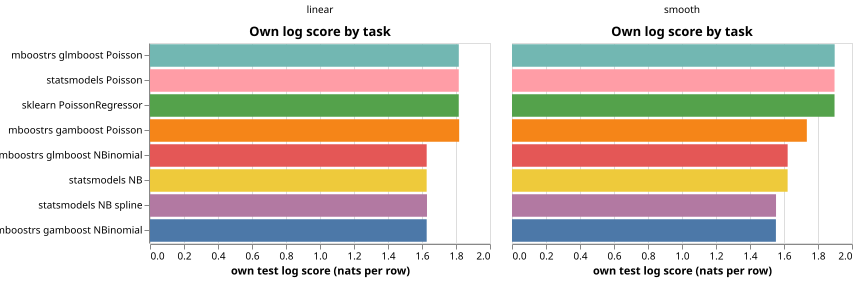

In [6]:
chart_rows = summary.filter(pl.col("method") != "generating NB")
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("own_nll:Q", title="own test log score (nats per row)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=340,
    height=200,
    title="Own log score by task",
).facet(column=alt.Column("task:N", title=None))


## The linear mean

`glmboost` with `NBinomial` matches the NB2 maximum likelihood fit. Mean own log score is {eval}`f"{value('linear', 'mboostrs glmboost NBinomial', 'own_nll'):.4f}"` nats per row, against {eval}`f"{value('linear', 'statsmodels NB', 'own_nll'):.4f}"` for statsmodels and {eval}`f"{value('linear', 'generating NB', 'own_nll'):.4f}"` for the generating distribution. The estimated size is {eval}`f"{value('linear', 'mboostrs glmboost NBinomial', 'size'):.2f}"` against {eval}`f"{value('linear', 'statsmodels NB', 'size'):.2f}"` and the generating value 1.5. Mean absolute error of the mean is {eval}`f"{value('linear', 'mboostrs glmboost NBinomial', 'mae'):.3f}"` and {eval}`f"{value('linear', 'statsmodels NB', 'mae'):.3f}"`. Cross-validation stopped inside the 500-step path on every seed (mean chosen step {eval}`f"{value('linear', 'mboostrs glmboost NBinomial', 'mstop'):.0f}"`). The NB2 fit takes a few milliseconds; the cross-validated boost takes about {eval}`f"{value('linear', 'mboostrs glmboost NBinomial', 'seconds'):.2f}"` seconds, because each step re-estimates the size.

The Poisson fit constrains its variance to equal its fitted mean, leaving the extra count variation unmodelled. Its own log score is {eval}`f"{value('linear', 'statsmodels Poisson', 'own_nll'):.3f}"` for statsmodels and {eval}`f"{value('linear', 'mboostrs glmboost Poisson', 'own_nll'):.3f}"` for `glmboost`, {eval}`f"{value('linear', 'statsmodels Poisson', 'own_nll') - value('linear', 'statsmodels NB', 'own_nll'):.2f}"` nats per row worse than the negative binomial. Scored at the true size, those same Poisson means are {eval}`f"{value('linear', 'statsmodels Poisson', 'nll_true'):.4f}"`, indistinguishable from the negative binomial's {eval}`f"{value('linear', 'statsmodels NB', 'nll_true'):.4f}"`. Absolute error is {eval}`f"{value('linear', 'statsmodels Poisson', 'mae'):.3f}"` against {eval}`f"{value('linear', 'statsmodels NB', 'mae'):.3f}"`. Here the Poisson mean predictions are close to those from the negative binomial, but its count probabilities fit the extra variation poorly. `PoissonRegressor` matches the Poisson GLM ({eval}`f"{value('linear', 'sklearn PoissonRegressor', 'own_nll'):.3f}"`).

On training seed 0 the variance is {eval}`f"{bench['recovery']['train_var_over_mean']:.2f}"` times the mean. statsmodels reports `alpha` {eval}`f"{bench['recovery']['statsmodels_alpha']:.3f}"`, which is a size of {eval}`f"{bench['recovery']['statsmodels_size']:.3f}"`. `nuisance()` is {eval}`f"{bench['recovery']['glmboost_size']:.3f}"`. In-sample `logLik()` is {eval}`f"{bench['recovery']['glmboost_loglik']:.1f}"` and equals the negative binomial log-likelihood summed over the training rows. The NB2 log-likelihood is {eval}`f"{bench['recovery']['statsmodels_llf']:.1f}"`. The slopes are close after `coef(off2int=True)`: `x1` {eval}`f"{bench['recovery']['glmboost_off2int']['x1']:.3f}"` against {eval}`f"{bench['recovery']['statsmodels_nb']['x1']:.3f}"`, `x2` {eval}`f"{bench['recovery']['glmboost_off2int']['x2']:.3f}"` against {eval}`f"{bench['recovery']['statsmodels_nb']['x2']:.3f}"`. The intercept is {eval}`f"{bench['recovery']['glmboost_off2int']['(Intercept)']:.3f}"` against {eval}`f"{bench['recovery']['statsmodels_nb']['Intercept']:.3f}"`. Without `off2int` the intercept is {eval}`f"{bench['recovery']['glmboost_raw_intercept']:.3f}"`, because the offset is stored separately. Early stopping leaves the coefficients a little short of the maximum likelihood estimates; the test log score does not show that gap.

A B-spline in `x1` is unused flexibility. Its own log score stays close ({eval}`f"{value('linear', 'statsmodels NB spline', 'own_nll'):.4f}"`) and its absolute error rises to {eval}`f"{value('linear', 'statsmodels NB spline', 'mae'):.3f}"`. `gamboost` with a P-spline on `x1` is in between (own log score {eval}`f"{value('linear', 'mboostrs gamboost NBinomial', 'own_nll'):.4f}"`, absolute error {eval}`f"{value('linear', 'mboostrs gamboost NBinomial', 'mae'):.3f}"`) and stops well short of 1,400 steps.


## The smooth mean

A linear negative binomial misses the sine. Its own log score is {eval}`f"{value('smooth', 'statsmodels NB', 'own_nll'):.3f}"` and `glmboost` with the same linear formula scores {eval}`f"{value('smooth', 'mboostrs glmboost NBinomial', 'own_nll'):.3f}"`. Absolute error is {eval}`f"{value('smooth', 'statsmodels NB', 'mae'):.3f}"` and {eval}`f"{value('smooth', 'mboostrs glmboost NBinomial', 'mae'):.3f}"`. The estimated size falls to about {eval}`f"{value('smooth', 'statsmodels NB', 'size'):.2f}"`, because the missed curve is absorbed into the variance. The generating density scores {eval}`f"{value('smooth', 'generating NB', 'own_nll'):.3f}"`.

`gamboost` with `bbs(x1) + bols(x2) + bols(noise)` scores {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'own_nll'):.4f}"`. The B-spline NB2 fit scores {eval}`f"{value('smooth', 'statsmodels NB spline', 'own_nll'):.4f}"`. Absolute error is {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'mae'):.3f}"` against {eval}`f"{value('smooth', 'statsmodels NB spline', 'mae'):.3f}"`. Both recover a size near {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'size'):.2f}"`. Both beat the linear negative binomial by about 0.07 nats per row. The boost takes about {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'seconds'):.1f}"` seconds against a few hundredths for the spline MLE. The spline MLE fits the specified basis directly. Boosting selects among candidate learners at each update, allowing it to fit `x1` while leaving `noise` unused.

{eval}`f"{n_at_cap('smooth', 'mboostrs gamboost NBinomial')}"` of the four `gamboost` paths was still falling at 1,400 steps. On that seed the test log score was already level with the spline (the four-seed means above include it). The other paths stopped inside the budget; the mean chosen step is {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'mstop'):.0f}"`.

The smooth Poisson can approximate the generating mean while still constraining variance to equal that mean. `gamboost` with `Poisson` scores {eval}`f"{value('smooth', 'mboostrs gamboost Poisson', 'nll_true'):.4f}"` at the true size, next to the negative binomial's {eval}`f"{value('smooth', 'mboostrs gamboost NBinomial', 'nll_true'):.4f}"`, and its own Poisson log score is {eval}`f"{value('smooth', 'mboostrs gamboost Poisson', 'own_nll'):.3f}"`. The linear Poisson is worse on both: own log score {eval}`f"{value('smooth', 'statsmodels Poisson', 'own_nll'):.3f}"`, absolute error {eval}`f"{value('smooth', 'statsmodels Poisson', 'mae'):.3f}"`.


## Prediction and parameter accessors

The probes below are the calls recorded in `bench_negbin.json` on the first linear training sample.

`predict` defaults to `type="link"`. For `NBinomial` that is the log mean, and `type="response"` is the mean. On this sample the two agree with `exp` to {eval}`probe("predict default is the log mean")["detail"].split("to ")[1].split(". The")[0]`. The benchmark uses `type="response"`.

Issue 207: `nuisance()` is the size in `Var = mu + mu**2 / sigma`, not the NB2 dispersion. On a 40-step path this sample reports {eval}`probe("NBinomial nuisance is the size")["detail"].split(". Variance")[0]`. Seed 0 of the benchmark, after cross-validation, reports size {eval}`f"{bench['recovery']['glmboost_size']:.3f}"` against statsmodels `alpha` {eval}`f"{bench['recovery']['statsmodels_alpha']:.3f}"`. Using the nuisance value as `alpha` makes the extra-Poisson variance about {eval}`f"{bench['recovery']['glmboost_size'] ** 2:.1f}"` times too large. The class docstring now states the variance and the reciprocal. The parameterization is the one R's `NBinomial` uses; it was not changed.

`coef()` without `off2int` drops the offset. The raw intercept on seed 0 is {eval}`f"{bench['recovery']['glmboost_raw_intercept']:.3f}"`; the intercept that lines up with the NB2 fit is {eval}`f"{bench['recovery']['glmboost_off2int']['(Intercept)']:.3f}"`.

`autospec` with no budget names `Poisson`. The counts are whole numbers stored as floating point, so it warns and assumes Poisson until something is measured:

> {eval}`probe("autospec without a budget")["detail"]`

Passing a budget that pays for the family probe switches to `NBinomial` and reports a held-out Pearson dispersion above 1:

> {eval}`probe("autospec with a family-probe budget")["detail"]`

A caller who fits the object `autospec` returns without a budget gets the Poisson column of the table above. The probe is the step that sees the extra variance. It is not run by the default call.

A negative count is refused with the family name and the failing value:

> {eval}`probe("NBinomial rejects a negative count")["detail"]`

The Poisson baseline has no nuisance parameter. The recorded result is:

> {eval}`probe("glmboost Poisson nuisance()")["detail"]`

The recorded continuation and cross-validation probe reports:

> {eval}`probe("cvrisk after gamboost.continue_to")["detail"]`

Both the `gamboost` and `glmboost` continuation probes completed in this
artifact. For a path whose optimum reaches its cap, extend the path and
repeat cross-validation before deciding where to stop.
